In [7]:
import lancedb
from scipy.spatial import distance
from scipy.cluster.hierarchy import dendrogram, linkage
import matplotlib.pyplot as plt
import numpy as np

In [3]:
uri = "../../data/pokemon_db"
db = lancedb.connect(uri)

db.list_tables()

ListTablesResponse(context=None, tables=['pokemon'], page_token=None)

In [4]:
table = db.open_table("pokemon")
df = table.search().to_polars()

df

dex_num,name,page_title,image_path,text,use_image,vector
str,str,str,str,str,bool,"array[f32, 1024]"
"""0004""","""Charmander""","""Charmander (Pokémon)""","""data/pokemon_data/images/0004_…","""Charmander is a bipedal, repti…",true,"[0.007554, 0.030658, … 0.0053]"
"""0006""","""Charizard""","""Charizard (Pokémon)""","""data/pokemon_data/images/0006_…","""Charizard is a draconic , bipe…",true,"[0.016637, 0.02502, … -0.0019]"
"""0012""","""Butterfree""","""Butterfree (Pokémon)""","""data/pokemon_data/images/0012_…","""Butterfree is a lepidopteran i…",true,"[0.011366, 0.009898, … 0.00258]"
"""0013""","""Weedle""","""Weedle (Pokémon)""","""data/pokemon_data/images/0013_…","""Weedle is a larval insect Poké…",true,"[0.032541, 0.013124, … 0.003622]"
"""0014""","""Kakuna""","""Kakuna (Pokémon)""","""data/pokemon_data/images/0014_…","""Kakuna is a yellow, insect coc…",true,"[0.011231, 0.029003, … 0.000883]"
…,…,…,…,…,…,…
"""1019""","""Hydrapple""","""Hydrapple (Pokémon)""","""data/pokemon_data/images/1019_…","""Hydrapple is a Pokémon compose…",false,"[-1.925704, -0.637682, … 4.399613]"
"""1020""","""Gouging Fire""","""Gouging Fire (Pokémon)""","""data/pokemon_data/images/1020_…","""Gouging Fire is a massive lion…",false,"[-1.295118, 3.737894, … 2.221165]"
"""1022""","""Iron Boulder""","""Iron Boulder (Pokémon)""","""data/pokemon_data/images/1022_…","""Iron Boulder is a spherical, b…",false,"[2.732905, 6.297201, … -0.804262]"


In [56]:
df = df.sample(n=50, shuffle=False, seed=1)
df

dex_num,name,page_title,image_path,text,use_image,vector
str,str,str,str,str,bool,"array[f32, 1024]"
"""0032""","""Nidoran♂""","""Nidoran♂ (Pokémon)""","""data/pokemon_data/images/0032_…","""Nidoran♂ is a small, quadruped…",true,"[0.044863, 0.021108, … 0.021679]"
"""0054""","""Psyduck""","""Psyduck (Pokémon)""","""data/pokemon_data/images/0054_…","""Psyduck is a yellow Pokémon re…",true,"[0.013449, -0.005135, … -0.006852]"
"""0120""","""Staryu""","""Staryu (Pokémon)""","""data/pokemon_data/images/0120_…","""Staryu is a golden-brown, echi…",true,"[0.004019, 0.01939, … -0.000913]"
"""0137""","""Porygon""","""Porygon (Pokémon)""","""data/pokemon_data/images/0137_…","""Porygon is an artificial Pokém…",true,"[0.019341, 0.031788, … 0.020287]"
"""0146""","""Moltres""","""Moltres (Pokémon)""","""data/pokemon_data/images/0146_…","""Moltres is a large, avian Poké…",true,"[0.01006, 0.010598, … 0.026039]"
…,…,…,…,…,…,…
"""0874""","""Stonjourner""","""Stonjourner (Pokémon)""","""data/pokemon_data/images/0874_…","""Stonjourner is a tall Pokémon …",true,"[0.005135, 0.014214, … -0.018826]"
"""0923""","""Pawmot""","""Pawmot (Pokémon)""","""data/pokemon_data/images/0923_…","""Pawmot is a stout, bipedal, ro…",true,"[0.004871, -0.015991, … -0.016364]"
"""0934""","""Garganacl""","""Garganacl (Pokémon)""","""data/pokemon_data/images/0934_…","""Garganacl is a large, bipedal …",true,"[0.006161, 0.004044, … 0.019089]"


In [57]:
image_dict = dict(df["name", "use_image"].iter_rows())

image_dict

{'Nidoran♂': True,
 'Psyduck': True,
 'Staryu': True,
 'Porygon': True,
 'Moltres': True,
 'Dratini': True,
 'Mewtwo': True,
 'Meganium': True,
 'Ampharos': True,
 'Wartortle': False,
 'Raichu': False,
 'Growlithe': False,
 'Kingler': False,
 'Mr. Mime': False,
 'Steelix': False,
 'Quagsire': True,
 'Scizor': True,
 'Remoraid': True,
 'Mudkip': True,
 'Aron': True,
 'Claydol': True,
 'Wynaut': True,
 'Salamence': True,
 'Metang': True,
 'Teddiursa': False,
 'Pupitar': False,
 'Celebi': False,
 'Blaziken': False,
 'Gardevoir': False,
 'Grumpig': False,
 'Feebas': False,
 'Banette': False,
 'Beldum': False,
 'Empoleon': False,
 'Luxio': True,
 'Roserade': True,
 'Wormadam': True,
 'Phione': True,
 'Panpour': True,
 'Ducklett': True,
 'Tangrowth': False,
 'Solosis': False,
 'Quilladin': True,
 'Heliolisk': True,
 'Pyroar': False,
 'Stonjourner': True,
 'Pawmot': True,
 'Garganacl': True,
 'Wugtrio': True,
 'Centiskorch': False}

In [58]:
distance_matrix = distance.cdist(df["vector"], df["vector"], metric="cosine")
np.fill_diagonal(distance_matrix, 0)

distance_matrix

array([[0.        , 0.3053462 , 0.34111914, ..., 0.4654195 , 0.38194927,
        0.7938384 ],
       [0.3053462 , 0.        , 0.31741107, ..., 0.45447172, 0.3464853 ,
        0.84807828],
       [0.34111914, 0.31741107, 0.        , ..., 0.4394777 , 0.38427647,
        0.81726208],
       ...,
       [0.4654195 , 0.45447172, 0.4394777 , ..., 0.        , 0.44578545,
        0.81508519],
       [0.38194927, 0.3464853 , 0.38427647, ..., 0.44578545, 0.        ,
        0.71447614],
       [0.7938384 , 0.84807828, 0.81726208, ..., 0.81508519, 0.71447614,
        0.        ]], shape=(50, 50))

In [59]:
cond_distance_matrix = distance.squareform(distance_matrix)
cond_distance_matrix

array([0.3053462 , 0.34111914, 0.41516675, ..., 0.44578545, 0.81508519,
       0.71447614], shape=(1225,))

name
str
"""Nidoran♂"""
"""Psyduck"""
"""Staryu"""
"""Porygon"""
"""Moltres"""
…
"""Stonjourner"""
"""Pawmot"""
"""Garganacl"""


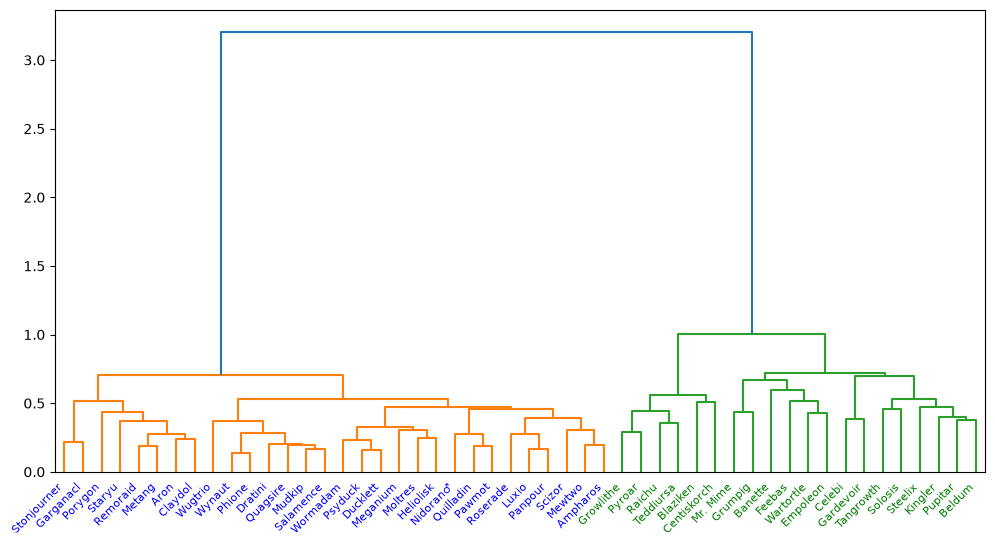

In [62]:
linkage_data = linkage(cond_distance_matrix, method='ward')

plt.figure(figsize=(12, 6))
ax = plt.subplot(111)
dendrogram(linkage_data, labels=df["name"])

for xtick in ax.get_xticklabels():
    if image_dict[xtick.get_text()]:
        xtick.set_color('b')
    else:
        xtick.set_color('g')

plt.xticks(rotation=45, ha="right")


plt.savefig("test_cluster.png")
plt.show()